In [1]:
%pip install -q -U sentence-transformers google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata, files, drive
from sentence_transformers import SentenceTransformer
from google import genai

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")
if not GEMINI_API_KEY:
    raise ValueError("Add GEMINI_API_KEY in Colab Secrets and enable notebook access.")
client = genai.Client(api_key=GEMINI_API_KEY)
GENERATION_MODEL = "gemini-3.8-flash"
print("Setup complete.")

Setup complete.


In [3]:
test_response = client.models.generate_content(
    model=GENERATION_MODEL,
    contents="Reply with exactly: Gemini connection successful."
)
print(test_response.text)

Gemini connection successful.


In [4]:
uploaded = files.upload()
csv_files = [n for n in uploaded if n.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Upload the Women's E-Commerce Clothing Reviews CSV.")
raw_df = pd.read_csv(csv_files[0])
raw_df = raw_df.loc[:, ~raw_df.columns.astype(str).str.match(r"^Unnamed")]
print("Dataset shape:", raw_df.shape)
display(raw_df.head())

Saving Womens Clothing E-Commerce Reviews.csv to Womens Clothing E-Commerce Reviews.csv
Dataset shape: (23486, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [5]:
required = ["Age", "Title", "Review Text", "Rating", "Recommended IND",
            "Positive Feedback Count", "Division Name", "Department Name", "Class Name"]
missing = [c for c in required if c not in raw_df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")

df = raw_df.copy()
for c in ["Title", "Review Text", "Division Name", "Department Name", "Class Name"]:
    df[c] = df[c].fillna("").astype(str).str.strip()
for c in ["Rating", "Age", "Recommended IND", "Positive Feedback Count"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["Positive Feedback Count"] = df["Positive Feedback Count"].fillna(0)
df = df.dropna(subset=["Review Text", "Rating"])
df = df[(df["Review Text"].str.len() > 0) & df["Rating"].between(1, 5)]
df = df.drop_duplicates(subset=["Review Text", "Rating", "Age"]).reset_index(drop=True)

df["Sentiment"] = np.where(df["Rating"] >= 4, "Positive",
                    np.where(df["Rating"] <= 2, "Negative", "Neutral"))
df["Review ID"] = [f"R{i:05d}" for i in range(1, len(df)+1)]
df["Embedding Text"] = (
    "Title: " + df["Title"] + "\\nReview: " + df["Review Text"] +
    "\\nDepartment: " + df["Department Name"] +
    "\\nClass: " + df["Class Name"] +
    "\\nRating: " + df["Rating"].astype(int).astype(str) +
    "\\nSentiment: " + df["Sentiment"]
)

SAMPLE_SIZE = 3000  # Set to None to use all cleaned reviews.
if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
    df["Review ID"] = [f"R{i:05d}" for i in range(1, len(df)+1)]
texts = df["Embedding Text"].tolist()
print("Reviews prepared:", len(df))
display(df[["Review ID", "Rating", "Sentiment", "Department Name", "Review Text"]].head())

Reviews prepared: 3000


,Review ID,Rating,Sentiment,Department Name,Review Text
0,R00001,5,Positive,Tops,This top is really pretty and nice quality. ru...
1,R00002,1,Negative,Intimate,I was so excited to splurge on a mara hoffman ...
2,R00003,5,Positive,Tops,Got so many complements! really comfy but runs...
3,R00004,5,Positive,Bottoms,I've ordered a pair of these from the catalog ...
4,R00005,5,Positive,Dresses,The dress is very beautiful and looks expensiv...


In [6]:
drive.mount("/content/drive")
PROJECT_DIR = "/content/drive/MyDrive/Ecommerce_RAG_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)
EMBEDDINGS_PATH = os.path.join(PROJECT_DIR, "minilm_embeddings.npy")
METADATA_PATH = os.path.join(PROJECT_DIR, "embedding_metadata.json")

Mounted at /content/drive


In [7]:
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
BATCH_SIZE = 64
fingerprint = hashlib.sha256("\\n".join(texts).encode("utf-8")).hexdigest()
model = SentenceTransformer(EMBEDDING_MODEL_NAME)

vectors, completed = None, 0
if os.path.exists(EMBEDDINGS_PATH) and os.path.exists(METADATA_PATH):
    try:
        with open(METADATA_PATH) as f:
            meta = json.load(f)
        cached = np.load(EMBEDDINGS_PATH)
        if (meta.get("fingerprint") == fingerprint and
            meta.get("model") == EMBEDDING_MODEL_NAME and
            cached.ndim == 2 and cached.shape[1] == 384 and
            cached.shape[0] <= len(texts)):
            vectors, completed = cached.astype("float32"), len(cached)
            print(f"Resuming at {completed} embeddings.")
    except Exception as e:
        print("Cache not reusable; starting again:", e)

if vectors is None:
    vectors = np.empty((0, 384), dtype="float32")

for start in range(completed, len(texts), BATCH_SIZE):
    batch_vec = model.encode(texts[start:start+BATCH_SIZE],
        batch_size=BATCH_SIZE, convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=False).astype("float32")
    vectors = np.vstack([vectors, batch_vec])
    np.save(EMBEDDINGS_PATH, vectors)
    with open(METADATA_PATH, "w") as f:
        json.dump({"model": EMBEDDING_MODEL_NAME, "fingerprint": fingerprint,
                   "completed": len(vectors), "dimension": int(vectors.shape[1])}, f)
    print(f"Embedded {len(vectors)}/{len(texts)}")

embeddings = vectors
if len(embeddings) != len(df):
    raise RuntimeError(f"Embedding count {len(embeddings)} != review count {len(df)}")
print("Embedding matrix:", embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedded 64/3000
Embedded 128/3000
Embedded 192/3000
Embedded 256/3000
Embedded 320/3000
Embedded 384/3000
Embedded 448/3000
Embedded 512/3000
Embedded 576/3000
Embedded 640/3000
Embedded 704/3000
Embedded 768/3000
Embedded 832/3000
Embedded 896/3000
Embedded 960/3000
Embedded 1024/3000
Embedded 1088/3000
Embedded 1152/3000
Embedded 1216/3000
Embedded 1280/3000
Embedded 1344/3000
Embedded 1408/3000
Embedded 1472/3000
Embedded 1536/3000
Embedded 1600/3000
Embedded 1664/3000
Embedded 1728/3000
Embedded 1792/3000
Embedded 1856/3000
Embedded 1920/3000
Embedded 1984/3000
Embedded 2048/3000
Embedded 2112/3000
Embedded 2176/3000
Embedded 2240/3000
Embedded 2304/3000
Embedded 2368/3000
Embedded 2432/3000
Embedded 2496/3000
Embedded 2560/3000
Embedded 2624/3000
Embedded 2688/3000
Embedded 2752/3000
Embedded 2816/3000
Embedded 2880/3000
Embedded 2944/3000
Embedded 3000/3000
Embedding matrix: (3000, 384)


In [8]:
def get_query_embedding(question):
    return model.encode([question], convert_to_numpy=True,
                        normalize_embeddings=True, show_progress_bar=False)[0].astype("float32")

def retrieve_reviews(question, top_k=5, department=None, max_rating=None):
    scores = embeddings @ get_query_embedding(question)
    results = df.copy()
    results["_score"] = scores
    if department:
        results = results[results["Department Name"].str.casefold() == department.casefold()]
    if max_rating is not None:
        results = results[results["Rating"] <= max_rating]
    return results.sort_values("_score", ascending=False).head(top_k).drop(
        columns=["Embedding Text"], errors="ignore").reset_index(drop=True)

display(retrieve_reviews("Customer comments about sizing and fit", top_k=5)[
    ["Review ID", "Rating", "Department Name", "Class Name", "_score", "Review Text"]])

,Review ID,Rating,Department Name,Class Name,_score,Review Text
0,R02110,4,Intimate,Swim,0.557334,These run really small..almost 2 sizes up. so ...
1,R00660,4,Intimate,Intimates,0.546810,"Good design, comfortable fit. however, sizing ..."
2,R01147,5,Bottoms,Pants,0.525876,Super flattering and lovely material. dress-up...
3,R01194,4,Bottoms,Pants,0.523353,Pants fit great. true to size. did not stretch...
4,R02417,5,Bottoms,Pants,0.518202,Perfect fit. did not lose its shape. thicker m...


In [9]:
def answer_with_rag(question, top_k=5, department=None, max_rating=None):
    results = retrieve_reviews(question, top_k, department, max_rating)
    if results.empty:
        return "I could not find relevant reviews in the dataset.", results

    context = "\n\n".join(
        f"[{r['Review ID']}] Rating: {r['Rating']}/5 | Department: {r['Department Name']} | "
        f"Class: {r['Class Name']} | Sentiment: {r['Sentiment']} | Review: {r['Review Text']}"
        for _, r in results.iterrows()
    )

    prompt = f'''You are an e-commerce customer insights assistant.
Answer using ONLY the customer reviews in the context. Do not invent facts, percentages,
or opinions. If evidence is insufficient, say so. Summarize recurring themes only when
multiple reviews support them. Cite supporting review IDs in square brackets.

CUSTOMER REVIEW CONTEXT:
{context}

QUESTION:
{question}
'''

    response = client.models.generate_content(
        model=GENERATION_MODEL,
        contents=prompt
    )
    return response.text, results


question = "What do customers say about clothing fit and sizing?"
answer, sources = answer_with_rag(question, top_k=5)
print(answer)
print("\nRetrieved source reviews:")
display(sources[["Review ID", "Rating", "Department Name", "Class Name", "_score", "Review Text"]])


Based on the provided reviews, customers share the following feedback regarding fit and sizing:

**Recurring Themes**
* **True to Size:** Multiple customers report that items run true to size or align with the size they normally purchase [R00543, R01147, R02023].
* **Flattering Cut:** Reviewers frequently describe the fit as flattering, noting that garments fit well without being overly tight or adding bulk [R01147, R00013, R02023].

**Specific Fit & Sizing Details**
* **Tops & Sweaters:** 
  * One blouse is noted to have a comfortable, slightly looser cut; the reviewer found an extra small was too tight in the shoulders, while their usual size small fit true to size [R00543].
  * A sweater is described as fitting perfectly for a chest-heavy frame (32H, 5'3") and hiding a post-pregnancy stomach without making the wearer look bigger; the customer ordered their usual medium [R02023].
* **Pants & Jumpsuits:** 
  * A jumpsuit is described as "fitted but not tight," with a self-tie belt pro

,Review ID,Rating,Department Name,Class Name,_score,Review Text
0,R00543,5,Tops,Blouses,0.580948,This is a comfortable and easy shirt that is m...
1,R01147,5,Bottoms,Pants,0.561350,Super flattering and lovely material. dress-up...
2,R00013,5,Bottoms,Pants,0.549526,I purchased this early in summer and have worn...
3,R02023,5,Tops,Fine gauge,0.548468,"I'm 5'3, with a 32h chest. ive always had a ha..."
4,R01819,4,Intimate,Layering,0.545171,"I'm 5'5"" 127lbs. ordered size small. not sheer..."


In [10]:
questions = [
    "What are common reasons for negative customer feedback?",
    "What do customers say about product quality and fabric?",
    "What do customers like or dislike about Dresses?"
]

for q in questions:
    print("\n" + "=" * 80 + "\nQUESTION:", q)
    response, source_rows = answer_with_rag(q, top_k=5)
    print("\nANSWER:", response)
    print("SOURCE REVIEW IDS:", source_rows["Review ID"].tolist())



QUESTION: What are common reasons for negative customer feedback?

ANSWER: Based on the provided reviews, the recurring reasons for negative customer feedback supported by multiple reviews are:

* **Poor or Unflattering Fit:** Customers reported issues with how the garments fit, noting that the fit was either "terrible" [R00982] or unflattering (e.g., making the customer "look pregnant") [R00120].
* **Poor Fabric Quality and Durability:** Customers cited problems with the material, including "very poor quality" fabric and washed-out colors [R00982], as well as fabric wearing thin and developing holes after being worn only a couple of times [R02693].
* **Disappointment Relative to the Retailer's Usual Standards:** Multiple loyal shoppers expressed strong disappointment, describing items as "awful" and uncharacteristically poor compared to their typically positive experiences with the brand [R00982], [R00312] (with another reviewer also broadly condemning an item as "an awful dress" [R0

,Review Count
Rating,
1,123
2,224
3,323
4,646
5,1684


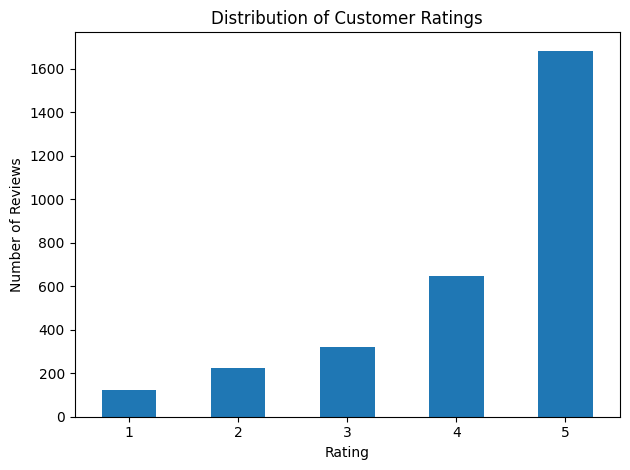

,Review Count
Sentiment,
Positive,2330
Negative,347
Neutral,323


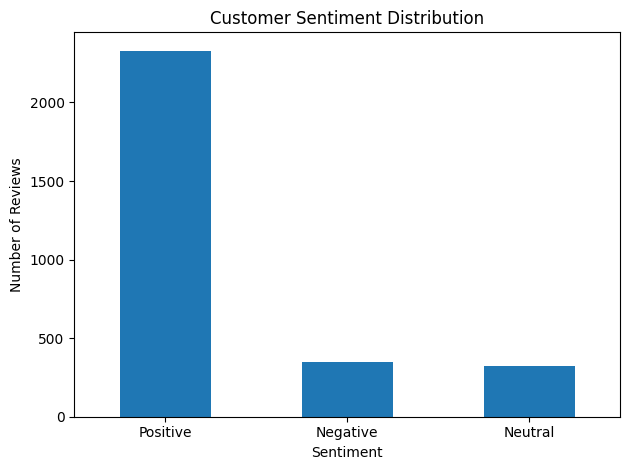

,mean,count
Department Name,,
,5.000000,1
Bottoms,4.261242,467
Jackets,4.236111,144
Tops,4.168287,1337
Intimate,4.167382,233
Dresses,4.158157,803
Trend,3.733333,15


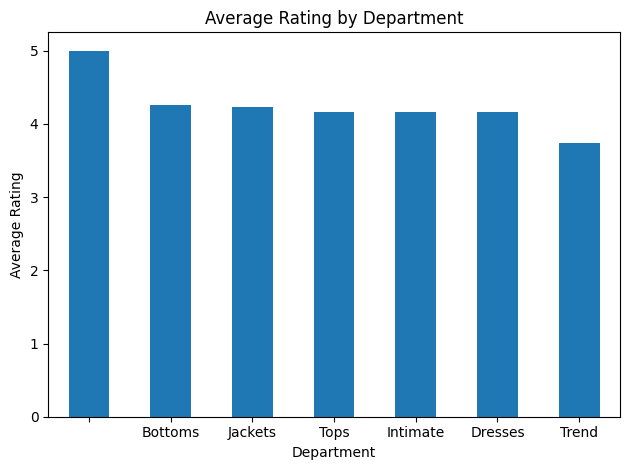

,Negative Review Count
Class Name,
Dresses,96
Knits,67
Blouses,50
Fine gauge,18
Pants,18
Sweaters,15
Jeans,14
Skirts,14
Jackets,14


Recommended IND,0,1,All
Rating,,,
1,122,1,123
2,202,22,224
3,209,114,323
4,27,619,646
5,3,1681,1684
All,563,2437,3000


In [11]:
rating_counts = df["Rating"].value_counts().sort_index()
display(rating_counts.rename_axis("Rating").to_frame("Review Count"))
rating_counts.plot(kind="bar", rot=0)
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating"); plt.ylabel("Number of Reviews"); plt.tight_layout(); plt.show()

sentiment_counts = df["Sentiment"].value_counts()
display(sentiment_counts.rename_axis("Sentiment").to_frame("Review Count"))
sentiment_counts.plot(kind="bar", rot=0)
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment"); plt.ylabel("Number of Reviews"); plt.tight_layout(); plt.show()

department_ratings = df.groupby("Department Name")["Rating"].agg(["mean", "count"]).sort_values("mean", ascending=False)
display(department_ratings)
department_ratings["mean"].plot(kind="bar", rot=0)
plt.title("Average Rating by Department")
plt.xlabel("Department"); plt.ylabel("Average Rating"); plt.tight_layout(); plt.show()

negative_reviews = df[df["Rating"] <= 2]
display(negative_reviews.groupby("Class Name").size().sort_values(ascending=False)
        .head(10).rename("Negative Review Count").to_frame())
display(pd.crosstab(df["Rating"], df["Recommended IND"], margins=True))

In [12]:
df.drop(columns=["Embedding Text"], errors="ignore").to_csv(
    os.path.join(PROJECT_DIR, "cleaned_customer_reviews.csv"), index=False)
rating_counts.rename_axis("Rating").to_frame("Review Count").to_csv(
    os.path.join(PROJECT_DIR, "rating_distribution.csv"))
department_ratings.to_csv(os.path.join(PROJECT_DIR, "department_rating_summary.csv"))
sentiment_counts.rename_axis("Sentiment").to_frame("Review Count").to_csv(
    os.path.join(PROJECT_DIR, "sentiment_distribution.csv"))
print("Saved outputs to:", PROJECT_DIR)

Saved outputs to: /content/drive/MyDrive/Ecommerce_RAG_Project
